# Visualizing Eaton and Palisades Fire Scars

Author: Erin Yang

[Github Repo](https://github.com/cloover7/eds220-hwk4)

# About
Purpose: what is this notebook about?
Highlights: List of highlights of analysis (3 or 4 highlights). What do you consider to be the most important aspects of this coding exercise?
About the data: Datasets description
References: Formal references to datasets. You can use the APA style as outlined here.


In [99]:
# import packages
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray as rioxr
import matplotlib.pyplot as plt
import os

# Fire Data Exploration

In [100]:
# load data
eaton = gpd.read_file(os.path.join('data', 'Eaton_Perimeter_20250121', 'Eaton_Perimeter_20250121.shp'))
palisades = gpd.read_file(os.path.join('data', 'Palisades_Perimieter_20250121', 'Palisades_Perimieter_20250121.shp'))
landsat = xr.open_dataset('data/landsat8-2025-02-23-palisades-eaton.nc')

In [101]:
# print crs for eaton
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [102]:
# print palisades crs
palisades.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

We can see that the two fire perimeter datasets have the same CRS, EPSG: 4269. Since the descriptions tell us they are "Geographic 2D", we can assume that they are projected and not geographic. 

# NetCDF Data Exploration

_Data was loaded in the first data loading code chunk alongside the fire perimeter data._

In [103]:
# display landsat dims, coords, variables
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The dimensions of this dataset are 2742x1418, and there are 4 coordinates, x, y, time, and spatial_ref. It also has 5 variables: red, green, blue, nir08, and swir22.

# Restoring Geospatial Information

In [104]:
# attempt to print crs
print(landsat.rio.crs)

None


In [105]:
# check crs from 
print(landsat.spatial_ref.crs_wkt)

PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


In [106]:
# write crs
landsat.rio.write_crs(landsat.spatial_ref.crs_wkt, inplace = True)

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...

In [107]:
# print crs
print(landsat.rio.crs)

EPSG:32611


# True Color Image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


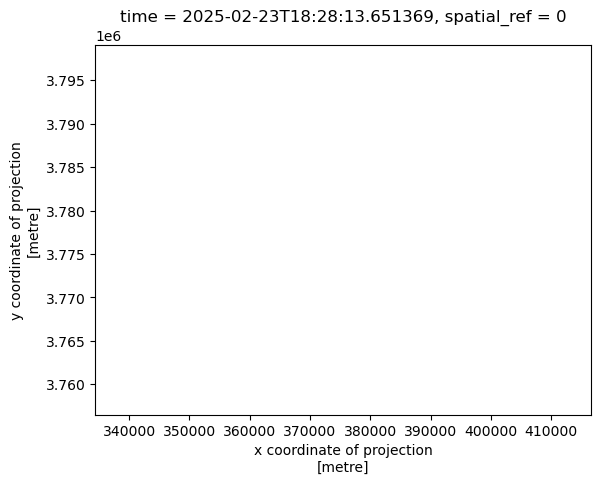

In [108]:
# plot red green and blue
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

In [109]:
np.isnan(landsat).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

There are a lot of NA values in the blue array!

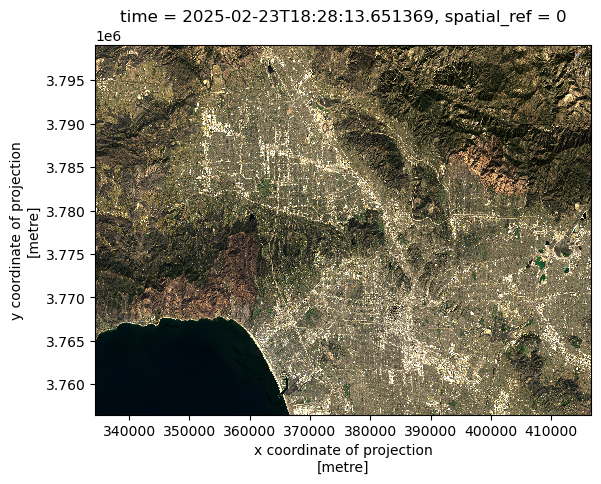

In [110]:
landsat[['red', 'green', 'blue']].fillna(0).to_dataarray().plot.imshow(robust = True)

Visually, the maps look almost identical. I cannot identify with the naked eye what the difference is between the two images. However, about 100 values in the blue array were converted to 0, so there is likely some less blue. 

# False Color Image

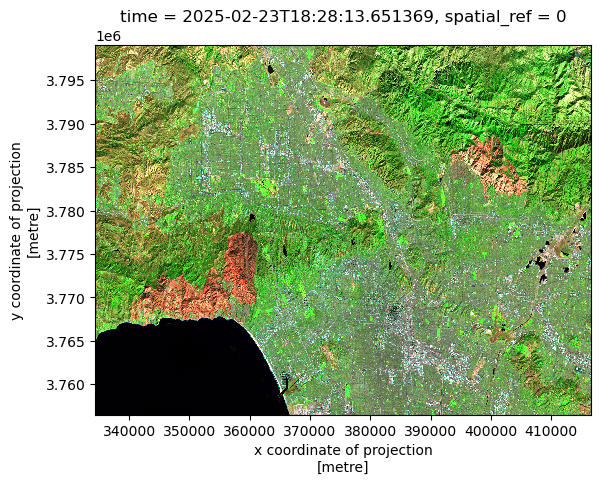

In [111]:
landsat[['swir22', 'nir08', 'red']].fillna(0).to_dataarray().plot.imshow(robust = True)

# Map

In [112]:
# make crs match
eaton = eaton.to_crs(landsat.rio.crs)
palisades = palisades.to_crs(landsat.rio.crs)

print(landsat.rio.crs == eaton.crs)

True


Text(0.5, 1.0, 'Palisades and Eaton Fires 2025')

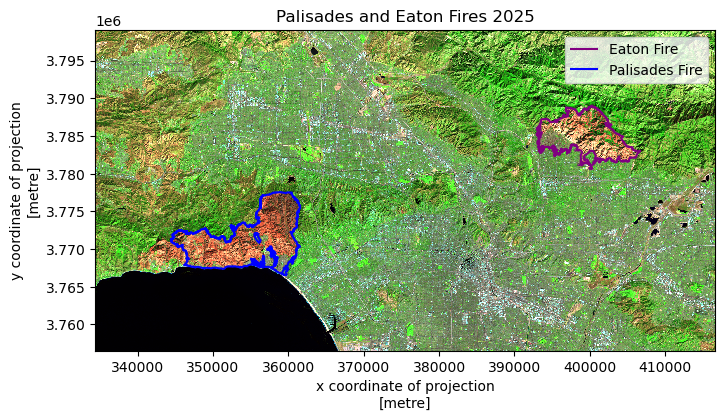

In [139]:
fig, ax = plt.subplots(figsize=(8, 6))
#ax.axis('off')

landsat[['swir22', 'nir08', 'red']].fillna(0).to_dataarray().plot.imshow(ax = ax, robust = True)

eaton.boundary.plot(ax=ax, color='purple', label = 'Eaton Fire')
palisades.boundary.plot(ax=ax, color='blue', label = 'Palisades Fire')

ax.legend()
ax.set_title('Palisades and Eaton Fires 2025')

This map uses False Color imagery to highlight the differences in vegetation in areas that were and weren't affected by the Eaton and Palisades fires. By using short wave infrared in the red channel and near infrared in the green channel, high and low vegetation areas are very distinctly colored. This map shows how strong the overlap is between low vegetation areas and the perimeters of the fires, and indicate that the fires did considerable damage to the vegetation.